# Solvers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TuLLI-AI/symprog/blob/main/notebooks/solver_tutorial.ipynb)

This notebook shows how to use `Solver`s to build, manipulate and perform inference over (weighted) Boolean formulas. It covers:

1. **Quick start**: adding formulas and weights, and looking inside a solver.
2. **Inference**: models, weighted model counting and probabilities, checked against a brute-force truth table.
3. **Evidence, queries and conditioning**: conditional probabilities.
4. **Generalized algebraic inference**: model counting, Viterbi, fuzzy logic and entropy as *semiring* computations, and how to define your own semiring.

Symbolic expressions and gradients are covered in `symbolic_and_gradients.ipynb`, and fast batched inference in `tensorization_and_jax.ipynb`.

## Setup

Install `symprog` with the notebook extras (uncomment the line below if you are running on Colab). Drawing circuits additionally requires the [Graphviz](https://graphviz.org/download/) system package; the rest of the notebook works without it. If `symprog` is not installed, the notebook uses the version in this repository.

In [1]:
# %pip install -q "symprog[notebooks]"

## use the installed symprog, or else the version in this repository
try:
    import symprog
except ImportError:
    import pathlib, sys
    repo = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "symprog" / "__init__.py").exists()), None)
    if repo is None:
        raise ImportError("symprog is not installed: pip install symprog, or run this notebook from the symprog repository")
    sys.path.insert(0, str(repo))
    import symprog

import itertools
import math
import shutil

import torch
from symprog import Solver

# Quick start

Solvers store Boolean formulas constructed from *Boolean variables* $a, b, c$. Below shows how to initialize a `Solver` instance and how to construct and add formulas using the `add` method.

In [2]:
solver = Solver()

### Adding formulas

Formulas are written as strings using `And`, `Or`, `Not`, `Implies`, `Biconditional` and `Xor` (or the operators `~`, `&` and `|`). A list of formulas is treated as their conjunction.

In [3]:
FORMULAS = [
    "Implies(a, b)",                 # a -> b
    "And(Or(a, b), Implies(a, c))",  # (a or b) and (a -> c)
]
solver.add(FORMULAS)

### Adding weights

Next we assign a weight $w(v) \in [0, 1]$ to each variable $v$, which we will interpret as the probability of $v$ being true.

In [4]:
WEIGHTS = {
    "a": 0.9,
    "b": 0.64,
    "c": 0.34,
}
solver.add_weights(WEIGHTS)

Each solver contains a set of `formulas`, a **weight backend** (an object for storing and manipulating weights) and a **solver backend** (an object for building formula objects and performing efficient inference over them).

In [5]:
solver

Solver(
  num_formulas=2,
  weight_backend=PytorchWeights,
  solver_backend=SddMapper,
  conditional=False,
)

Inference over formulas can then be achieved by doing the following (we describe inference in more detail in the next section). 

In [6]:
solver.inference()

SolverOut(inference_type=Prob, inference=0.2598400115966797)

#### Weight backends

By default, [PyTorch](https://pytorch.org/) is used for storing weights and performing numerical computation, which also gives us gradients (see the symbolic computation notebook). Other weight backends can be selected with `add_weights(..., container_type=...)`:

- `"python"`: plain Python/NumPy numbers (no gradients);
- `"sympy"` and `"symengine"`: symbolic weights, for computing exact symbolic expressions;
- `"jax"`: [JAX](https://docs.jax.dev/en/latest/notebooks/thinking_in_jax.html) arrays (**experimental**, requires `pip install "symprog[jax]"`).

The weight vector is ordered as in `solver.weight_names`:

In [7]:
print(solver.weights)
print(solver.weight_names, solver.weights.weights)

PytorchWeights(a=0.9, b=0.64, c=0.34)
['a', 'b', 'c'] tensor([0.9000, 0.6400, 0.3400])


#### Solver backends

By default, [pysdd](https://github.com/ML-KULeuven/PySDD) is used for building formula objects and *tractable circuits* for efficient inference, based on [Sentential Decision Diagrams (SDDs)](https://en.wikipedia.org/wiki/Sentential_decision_diagram). Formulas can also be built with [z3](https://ericpony.github.io/z3py-tutorial/guide-examples.htm) (SAT and SMT solving), [pysat](https://pysathq.github.io/) (SAT solving), [dd](https://pypi.org/project/dd/) ([Binary Decision Diagrams](https://en.wikipedia.org/wiki/Binary_decision_diagram)) and [sympy](https://www.sympy.org/), e.g., `Solver(_stype="z3")`. These backends currently support satisfiability checking, model counting and model enumeration, but weighted inference requires SDDs (see the [support table](https://github.com/TuLLI-AI/symprog#backend-support) in the README).

Below are the SDD objects for our two formulas:

In [8]:
solver.formulas

[SddNode(name=Decision,id=9), SddNode(name=Decision,id=13)]

The `solver.PrettyPrinting()` method returns a [Graphviz](https://graphviz.org/) drawing of the circuit for the conjunction of all formulas:

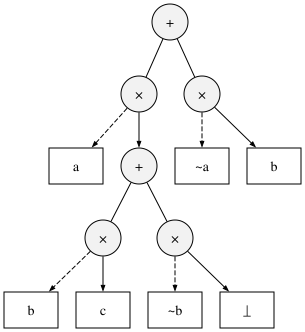

In [9]:
try:
    import graphviz
    has_graphviz = shutil.which("dot") is not None
except ImportError:
    has_graphviz = False

if has_graphviz:
    display(graphviz.Source(solver.PrettyPrinting().dot))
else:
    print("Install Graphviz (https://graphviz.org/download/) to draw the circuit.")

SDDs are the foundational data structure used for computing inference (for an overview see [**Darwiche, A. 2022**](https://arxiv.org/abs/2202.02942)). They are commonly used for *tractable* logical and probabilistic inference in many languages and libraries such as [problog](https://github.com/ML-KULeuven/problog), [scallop](https://github.com/scallop-lang) and [cirkit](https://github.com/april-tools/cirkit/blob/main/notebooks/logic-circuits.ipynb) (*we incorporate many implementation details from problog in particular*).

# Inference

The `query` method performs different forms of inference over the (weighted) formulas. Algorithmically, all of the inferences below reduce to variants of [**Weighted Model Counting**](https://www.sciencedirect.com/science/article/pii/S0004370207001889), or counting the propositional *models* (i.e., interpretations or possible worlds) of formulas.

#### Model enumeration

Below shows how to enumerate the models of our formulas using `solver.models()`:

In [10]:
for i, model in enumerate(solver.models()):
    print(f"model {i}: {model}")

model 0: {'a': True, 'b': True, 'c': True}
model 1: {'a': False, 'b': True, 'c': False}
model 2: {'a': False, 'b': True, 'c': True}


Each model $i$ is an assignment of the variables $a, b, c$ to truth values under which our formula $F$ (the conjunction of `FORMULAS`) is true, written $i \models F$.

#### A brute-force truth table

To check the solver's answers throughout this notebook, we will compute them by brute force, without using the solver at all. Below, $F$ is written as an ordinary Python function, and we enumerate all $2^3 = 8$ rows of its truth table.

In [11]:
VARIABLES = ["a", "b", "c"]

def F(a, b, c):
    """FORMULAS as a Python function: (a -> b) and (a or b) and (a -> c)."""
    return (not a or b) and (a or b) and (not a or c)

def worlds():
    """All assignments of VARIABLES to truth values (the rows of the truth table)."""
    for values in itertools.product([False, True], repeat=len(VARIABLES)):
        yield dict(zip(VARIABLES, values))

def world_weight(world, w):
    """Product of w(v) for true variables and 1 - w(v) for false ones."""
    return math.prod(w[v] if value else 1 - w[v] for v, value in world.items())

print(" ".join(f"{v:6}" for v in VARIABLES), "| F     | weight")
for i in worlds():
    print(" ".join(f"{str(i[v]):6}" for v in VARIABLES), f"| {str(F(**i)):5} | {world_weight(i, WEIGHTS):.4f}")

a      b      c      | F     | weight
False  False  False  | False | 0.0238
False  False  True   | False | 0.0122
False  True   False  | True  | 0.0422
False  True   True   | True  | 0.0218
True   False  False  | False | 0.2138
True   False  True   | False | 0.1102
True   True   False  | False | 0.3802
True   True   True   | True  | 0.1958


The rows where $F$ is true are exactly the models found by the solver:

In [12]:
MODELS = [i for i in worlds() if F(**i)]

def as_set(models):
    return {frozenset(m.items()) for m in models}

assert as_set(MODELS) == as_set(solver.models())

#### Weighted Model Counting (WMC)

We define a probability distribution over all assignments $i$ by weighting each row with the independent product of the weights of its variables, as in the `weight` column above. Weighted model counting sums the weights of the models of $F$:

$$\text{WMC}(F ; w) := \sum_{i \models F} \prod_{i \models v} w(v) \cdot \prod_{i \models \neg v} (1 - w(v))$$

Since the weights of all rows sum to one, this is the probability of $F$ being true:

$$Pr(F = 1; w) = \text{WMC}(F; w)$$

By brute force:

In [13]:
brute_force_prob = sum(world_weight(i, WEIGHTS) for i in MODELS)
brute_force_prob

0.25984

## Probabilistic inference

Of course, enumerating all models of a formula takes exponential time, which is where circuits become indispensable: given the circuit above, the probability of a formula can be computed in a single pass over the circuit, in time linear in its size. This is how `solver.query` performs inference, where the `mode` argument specifies the type of inference:

In [14]:
solver.query(mode="Prob")

SolverOut(inference_type=Prob, inference=0.2598400115966797)

which matches the brute-force computation:

In [15]:
assert math.isclose(solver.query(mode="Prob").inference.item(), brute_force_prob, rel_tol=1e-6)

The `LogProb` (*log probability*) mode performs the same computation in log space, which is more numerically stable for large formulas:

In [16]:
log_prob = solver.query(mode="LogProb").inference
assert math.isclose(log_prob.item(), math.log(brute_force_prob), rel_tol=1e-6)
log_prob

tensor(-1.3477)

## Evidence, queries and conditioning

#### Evidence

Evidence fixes the truth value of some variables, written as literals such as `"a"` or `"~a"` (several literals can be separated by spaces). Since variables are independent, this computes the conditional probability $Pr(F \mid a) = Pr(F \land a) / Pr(a)$:

In [17]:
p_F_given_a = solver.query(evidence="a").inference

brute_force = sum(world_weight(i, WEIGHTS) for i in MODELS if i["a"]) / WEIGHTS["a"]
assert math.isclose(p_F_given_a.item(), brute_force, rel_tol=1e-6)
p_F_given_a

tensor(0.2176)

#### Queries

A `query` asks for the probability of a literal *given* that $F$ holds, together with any evidence. For instance, $Pr(c \mid F, b)$:

In [18]:
p_c_given_F_b = solver.query(query="c", evidence="b").inference

numerator = sum(world_weight(i, WEIGHTS) for i in MODELS if i["b"] and i["c"])
denominator = sum(world_weight(i, WEIGHTS) for i in MODELS if i["b"])
assert math.isclose(p_c_given_F_b.item(), numerator / denominator, rel_tol=1e-6)
p_c_given_F_b

tensor(0.8374)

Without evidence, a query is conditioned on $F$ alone, giving $Pr(c \mid F) = Pr(F \land c) / Pr(F)$. Since $F$ already entails $b$, this is the same as the answer above:

In [19]:
p_c_given_F = solver.query(query="c").inference

brute_force = sum(world_weight(i, WEIGHTS) for i in MODELS if i["c"]) / brute_force_prob
assert math.isclose(p_c_given_F.item(), brute_force, rel_tol=1e-6)
assert math.isclose(p_c_given_F.item(), p_c_given_F_b.item(), rel_tol=1e-6)
p_c_given_F

tensor(0.8374)

#### Conditioning on formulas

More generally, `add_conditional` conditions on an arbitrary formula $G$, giving $Pr(F \mid G) = Pr(F \land G) / Pr(G)$:

In [20]:
def G(a, b, c):
    return a or c

solver.add_conditional("Or(a, c)")
p_F_given_G = solver.query().inference

brute_force = (
    sum(world_weight(i, WEIGHTS) for i in MODELS if G(**i))
    / sum(world_weight(i, WEIGHTS) for i in worlds() if G(**i))
)
assert math.isclose(p_F_given_G.item(), brute_force, rel_tol=1e-6)
p_F_given_G

tensor(0.2330)

Conditionals can be removed with `remove_conditional`:

In [21]:
solver.remove_conditional()
solver.query().inference

tensor(0.2598)

#### Satisfiability

Finally, the `SAT` mode checks whether the formulas (together with any evidence) are satisfiable. For example, $F$ requires $b$ to be true:

In [22]:
print(solver.query(mode="SAT").inference)
print(solver.query(mode="SAT", evidence="~b").inference)

yes
no


## Generalized algebraic inference

To capture other forms of inference, one can define a more general class of *Algebraic Model Counting* (AMC) problems [[**Kimmig et al. 2012**]](https://arxiv.org/pdf/1211.4475) (see also [[**Friesen et al. 2016**]](https://arxiv.org/abs/1611.03553)):

$$\text{AMC}(F; w) := \bigoplus_{i \models F} \bigotimes_{i \models l} w(l)$$

where $\oplus, \otimes$ denote *generalized sum and product operations* and $w$ is a generalized weight function over literals $l$ (i.e., a variable or its negation). By choosing different [semiring algebras](https://en.wikipedia.org/wiki/Semiring) $(D, \oplus, \otimes, \mathbf{0}, \mathbf{1})$ and weight functions $w(\cdot)$, a wide range of inferences can be expressed as AMC.

For example, the probability computation above uses the *probability semiring* $(\mathbb{R}_{\geq 0}, +, \times, 0, 1)$ with $w(v) \in [0, 1]$ and $w(\neg v) = 1 - w(v)$. Here $\mathbb{R}_{\geq 0}$ is the **domain** of the algebra, $+$ and $\times$ are the **sum and product operators** $\oplus, \otimes$, and $0$ and $1$ are the **additive and multiplicative identities** $\mathbf{0}, \mathbf{1}$.

Other inferences are specified algebraically below (all with $w(v) \in [0,1]$ and $w(\neg v) = 1 - w(v)$ unless stated otherwise):

- **LogProb** $\big(\mathbb{R}_{\leq 0} \cup \{-\infty\}, \text{logaddexp}, +, -\infty, 0\big)$ with log weights $\log w(l)$.

    Probability computation in log space, where $\text{logaddexp}(x, y) = \log (e^x + e^y)$ (as in [numpy](https://numpy.org/devdocs/reference/generated/numpy.logaddexp.html) and [pytorch](https://docs.pytorch.org/docs/stable/generated/torch.logaddexp.html)).

- **Count** $\big(\mathbb{N}, +, \times, 0, 1\big)$ with $w(v) = w(\neg v) = 1$.

    Unweighted model counting, or [#SAT](https://en.wikipedia.org/wiki/Sharp-SAT).

- **Viterbi** $\big(\mathbb{R}_{\geq 0}, \max, \times, 0, 1\big)$.

    The probability of the most likely model, also called the *Most Probable Explanation* (MPE). The `ViterbiAssignment` mode additionally returns the most likely model itself, and `LogViterbi` computes the same score in log space.

- **Fuzzy** $\big([0,1], \max, \min, 0, 1\big)$.

    Fuzzy logic inference using [Gödel logic](https://arxiv.org/pdf/2107.13646).

- **Entropy** $\big(\mathbb{R}_{\geq 0} \times \mathbb{R}, \oplus, \otimes, (0, 0), (1, 0)\big)$ with
    $$(p_1, h_1) \oplus (p_2, h_2) = (p_1 + p_2,\ h_1 + h_2) \qquad (p_1, h_1) \otimes (p_2, h_2) = (p_1 p_2,\ h_1 p_2 + h_2 p_1)$$
    and $w(l) = (w'(l), w'(l) \log w'(l))$, where $w'$ is the probability weight above.

    The result $(Z, S)$ gives the *semantic entropy*, or entropy of the interpretations $I$ given $F$, as $H(I \mid F) = \log Z - S / Z$ (see [Ahmed et al. 2022](https://proceedings.mlr.press/v180/ahmed22a.html), [Chang et al. 2023](https://arxiv.org/abs/2312.10087)). This is also known as the [entropy semiring](https://www.cs.jhu.edu/~jason/papers/eisner.fsmnlp01.pdf).

Each of these is selected with the `mode` argument:

In [23]:
MODES = ["Prob", "LogProb", "Count", "Viterbi", "LogViterbi", "Fuzzy", "Entropy"]

solver_results = {mode: solver.query(mode=mode).inference.item() for mode in MODES}
solver_results["ViterbiAssignment"] = solver.query(mode="ViterbiAssignment").variables
solver_results

{'Prob': 0.2598400115966797,
 'LogProb': -1.347689151763916,
 'Count': 3.0,
 'Viterbi': 0.1958400011062622,
 'LogViterbi': -1.6304572820663452,
 'Fuzzy': 0.3400000035762787,
 'Entropy': 0.716130256652832,
 'ViterbiAssignment': {'a': True, 'c': True, 'b': True}}

As before, we can check each of these by brute force over the truth table, where each line below mirrors the semiring definition above:

In [24]:
def brute_force_inferences(w):
    """All of the inferences above, computed by enumerating the models of F."""
    scores = [world_weight(i, w) for i in MODELS]
    Z = sum(scores)
    best = max(range(len(MODELS)), key=lambda k: scores[k])
    return {
        "Prob": Z,
        "LogProb": math.log(Z),
        "Count": len(MODELS),
        "Viterbi": scores[best],
        "LogViterbi": math.log(scores[best]),
        "Fuzzy": max(min(w[v] if value else 1 - w[v] for v, value in i.items()) for i in MODELS),
        "Entropy": -sum(s / Z * math.log(s / Z) for s in scores),
        "ViterbiAssignment": MODELS[best],
    }

brute_force = brute_force_inferences(WEIGHTS)

print(f"{'mode':<12} {'solver':>10} {'brute force':>12}")
for mode in MODES:
    print(f"{mode:<12} {solver_results[mode]:>10.5f} {brute_force[mode]:>12.5f}")
    assert math.isclose(solver_results[mode], brute_force[mode], rel_tol=1e-5)

assert solver_results["ViterbiAssignment"] == brute_force["ViterbiAssignment"]

mode             solver  brute force
Prob            0.25984      0.25984
LogProb        -1.34769     -1.34769
Count           3.00000      3.00000
Viterbi         0.19584      0.19584
LogViterbi     -1.63046     -1.63046
Fuzzy           0.34000      0.34000
Entropy         0.71613      0.71613


## Implementing new algebras

The library is designed to make it easy to implement new forms of reasoning. The example below implements a new semiring and registers it with the `SemiringRegistry`: the **Łukasiewicz** semiring, an alternative form of fuzzy reasoning to the Gödel logic above (see [[van Krieken et al. 2021]](https://arxiv.org/pdf/2002.06100)). It uses the Łukasiewicz *t-norm* $\max(0, x + y - 1)$ for conjunction and $\max$ for disjunction.

In [25]:
from symprog.solvers.semiring import Semiring, SemiringRegistry

@SemiringRegistry("Lukasiewicz")
class Lukasiewicz(Semiring):
    """Implementation of the Lukasiewicz fuzzy semiring.

    Methods:
        one: Implementation of the multiplicative identity.
        zero: Implementation of the additive identity.
        product: Implementation of the product operator.
        sum: Implementation of the sum operator.
        negation: Implementation of the weight negation operator.
    """
    def one(self):
        """Returns one"""
        return self._mgr.one()
    def zero(self):
        """Returns zero"""
        return self._mgr.zero()
    def product(self, x, y):
        """Returns max(0, x + y - 1)"""
        return self._mgr.max(0, x + y - 1)
    def sum(self, x, y):
        """Returns max(x, y)"""
        return self._mgr.max(x, y)
    def negation(self, x):
        """Implements `strong negation`, or w(~v) = 1 - w(v)"""
        return self._mgr.neg(x)

Once registered, the new algebra can be used directly through the `mode` argument (re-running the cell above simply replaces the registered definition):

In [26]:
solver.query(mode="Lukasiewicz")

SolverOut(inference_type=Lukasiewicz, inference=0.0)

The answer is $0$! Chaining the t-norm over the $n$ literals of a model gives $\max\big(0, \sum_l w(l) - (n - 1)\big)$, so a model only scores above zero if its literals are nearly certain: here that requires their weights to sum to more than $2$, which none of our models do. With more confident weights, the result is non-zero:

In [27]:
CONFIDENT_WEIGHTS = {"a": 0.95, "b": 0.9, "c": 0.8}

confident_solver = Solver()
confident_solver.add(FORMULAS)
confident_solver.add_weights(CONFIDENT_WEIGHTS)
lukasiewicz = confident_solver.query(mode="Lukasiewicz").inference

def lukasiewicz_and(values):
    return max(0.0, sum(values) - (len(values) - 1))

brute_force = max(
    lukasiewicz_and([CONFIDENT_WEIGHTS[v] if value else 1 - CONFIDENT_WEIGHTS[v] for v, value in i.items()])
    for i in MODELS
)
assert math.isclose(lukasiewicz.item(), brute_force, rel_tol=1e-5)
lukasiewicz

tensor(0.6500)

## Next steps

- **Symbolic computation and gradients** (`symbolic_and_gradients.ipynb`): computing the symbolic expressions behind these inferences, and their gradients with respect to the weights.
- **Tensorization and JAX** (`tensorization_and_jax.ipynb`): compiling inference for fast, batched evaluation.
- **Languages** (`languages.ipynb`): writing probabilistic programs in Python syntax, which are compiled to solvers like the ones above.